<a href="https://colab.research.google.com/github/kbliml/PracAI/blob/main/notebooke9b7e69654.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


Kaggle credentials set.
Kaggle credentials successfully validated.


In [6]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

playground_series_s6e11_path = kagglehub.competition_download('playground-series-s6e11')

print('Data source import complete.')


100%|██████████| 29.5M/29.5M [00:00<00:00, 169MB/s]

Extracting files...


Data source import complete.


In [7]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 다운로드된 실제 경로를 지정합니다.
path = playground_series_s6e11_path + "/"

train = pd.read_csv(path + "train.csv")
test = pd.read_csv(path + "test.csv")
submission = pd.read_csv(path + "sample_submission.csv")

print("Train:", train.shape, "Test:", test.shape)
display(train.head())

Train: (699960, 26) Test: (299984, 25)


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


Missing values: 0
is_fraud
0.0    98.33
1.0     1.67
Name: proportion, dtype: float64


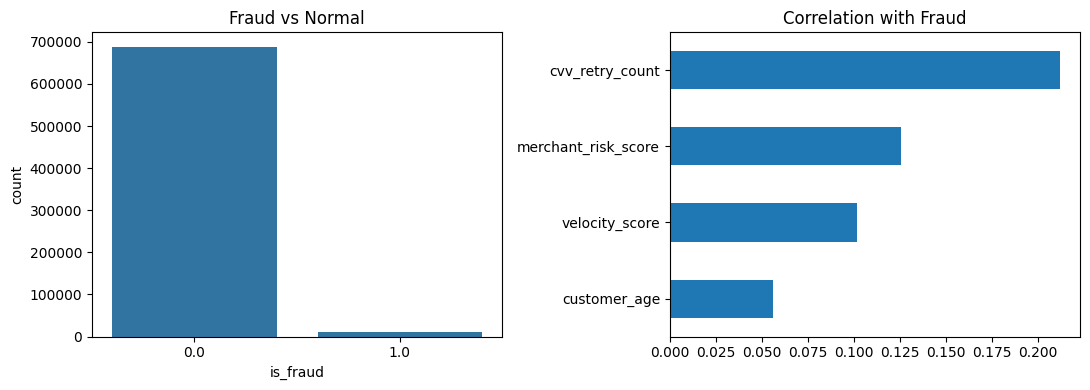

In [11]:
print("Missing values:", train.isna().sum().sum())
print(train["is_fraud"].value_counts(normalize=True).mul(100).round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=train, x="is_fraud", ax=ax[0])
ax[0].set_title("Fraud vs Normal")

features = ["merchant_risk_score", "velocity_score", "cvv_retry_count", "customer_age"]
correlations = train[features + ["is_fraud"]].corr(numeric_only=True)["is_fraud"].drop("is_fraud")
correlations.sort_values().plot.barh(ax=ax[1])
ax[1].set_title("Correlation with Fraud")
plt.tight_layout()
plt.show()

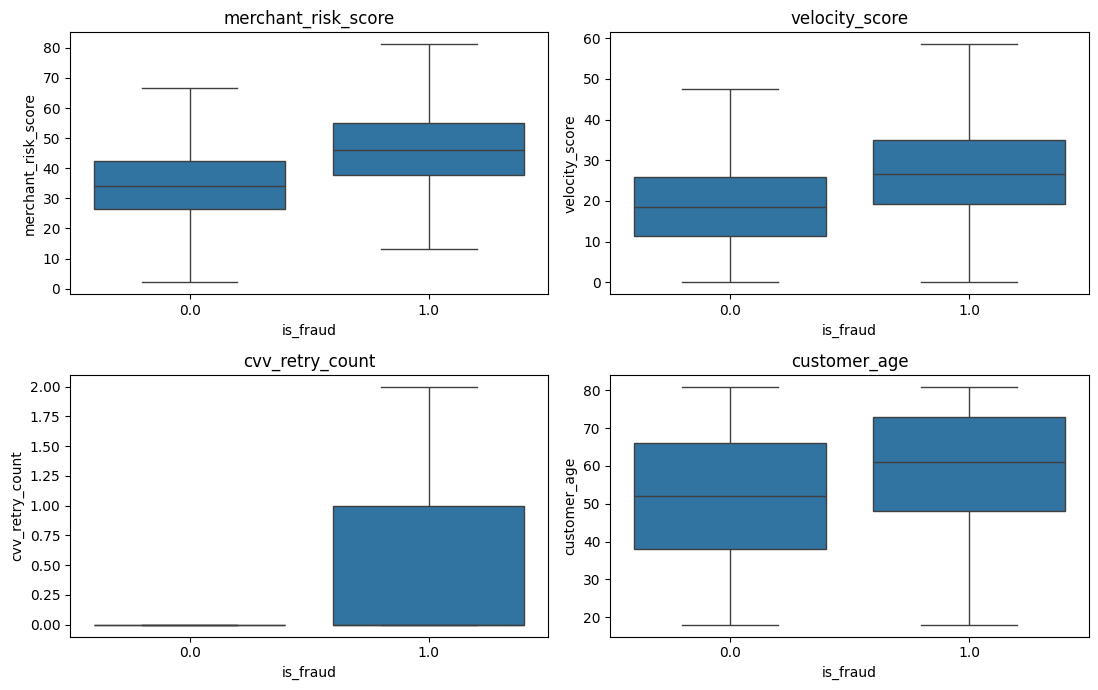

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for feature, ax in zip(features, axes.flat):
    sns.boxplot(data=train, x="is_fraud", y=feature, showfliers=False, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = train.drop(columns=["id", "is_fraud"])
y = train["is_fraud"].astype(int)
X_test = test.drop(columns=["id"])

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric = X.select_dtypes(include=np.number).columns.tolist()
categorical = X.columns.difference(numeric).tolist()

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32))
    ]), categorical)
])

X_train = preprocess.fit_transform(X_train).astype("float32")
X_valid = preprocess.transform(X_valid).astype("float32")
X_test = preprocess.transform(X_test).astype("float32")
print("Model input shape:", X_train.shape)

Model input shape: (559968, 60)


In [14]:
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(name="auc")])
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weights = {0: float(weights[0]), 1: float(weights[1])}

history = model.fit(
    X_train, y_train, validation_data=(X_valid, y_valid),
    epochs=30, batch_size=512, class_weight=class_weights,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_auc", mode="max", patience=5, restore_best_weights=True)],
    verbose=1
)

Epoch 1/30
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - auc: 0.9242 - loss: 0.3502 - val_auc: 0.9385 - val_loss: 0.2940
Epoch 2/30
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - auc: 0.9379 - loss: 0.3176 - val_auc: 0.9395 - val_loss: 0.2959
Epoch 3/30
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - auc: 0.9406 - loss: 0.3109 - val_auc: 0.9397 - val_loss: 0.2977
Epoch 4/30
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - auc: 0.9413 - loss: 0.3092 - val_auc: 0.9401 - val_loss: 0.3024
Epoch 5/30
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - auc: 0.9426 - loss: 0.3059 - val_auc: 0.9397 - val_loss: 0.3028
Epoch 6/30
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - auc: 0.9430 - loss: 0.3051 - val_auc: 0.9400 - val_loss: 0.3016
Epoch 7/30
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - auc: 0.9443 - loss: 0.3017 - val_auc: 0.9397 - val_loss: 0.2896
Epoch 8/30
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - auc: 0.9453 - loss: 0.2990 - val_auc: 0.9395 - val_loss: 0.3054
Epoch 9/30
1094/1094 ━━━━━━━━━━━━━━━━━━━

ROC-AUC: 0.94009
PR-AUC (Average Precision): 0.49606
              precision    recall  f1-score   support

           0       1.00      0.87      0.93    137654
           1       0.10      0.86      0.18      2338

    accuracy                           0.87    139992
   macro avg       0.55      0.87      0.56    139992
weighted avg       0.98      0.87      0.92    139992



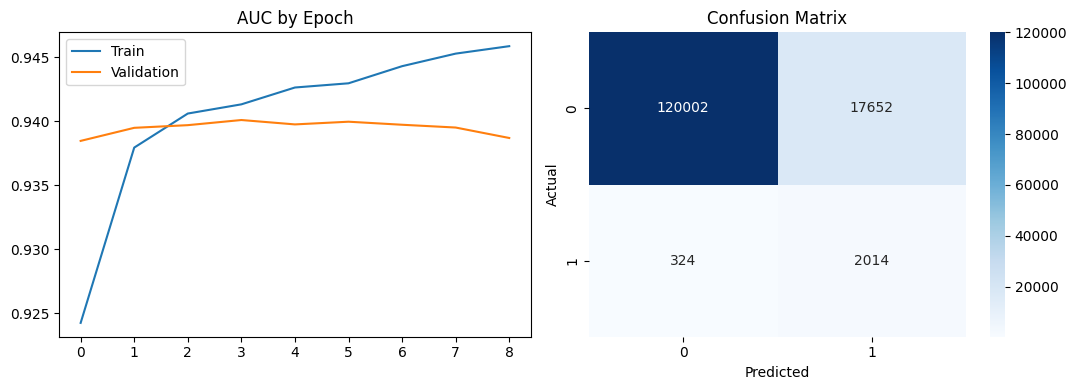

In [15]:
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, classification_report

valid_prob = model.predict(X_valid, verbose=0).ravel()
valid_label = (valid_prob >= 0.5).astype(int)
print("ROC-AUC:", round(roc_auc_score(y_valid, valid_prob), 5))
print("PR-AUC (Average Precision):", round(average_precision_score(y_valid, valid_prob), 5))
print(classification_report(y_valid, valid_label, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history["auc"], label="Train")
axes[0].plot(history.history["val_auc"], label="Validation")
axes[0].set_title("AUC by Epoch")
axes[0].legend()
sns.heatmap(confusion_matrix(y_valid, valid_label), annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set(xlabel="Predicted", ylabel="Actual", title="Confusion Matrix")
plt.tight_layout()
plt.show()

In [16]:
submission["is_fraud"] = model.predict(X_test, verbose=0).ravel()
submission.to_csv("submission.csv", index=False)
display(submission.head())
print("Saved submission.csv")

,id,is_fraud
0,699960,0.013252
1,699961,0.005526
2,699962,0.786836
3,699963,0.075958
4,699964,0.159547


Saved submission.csv
